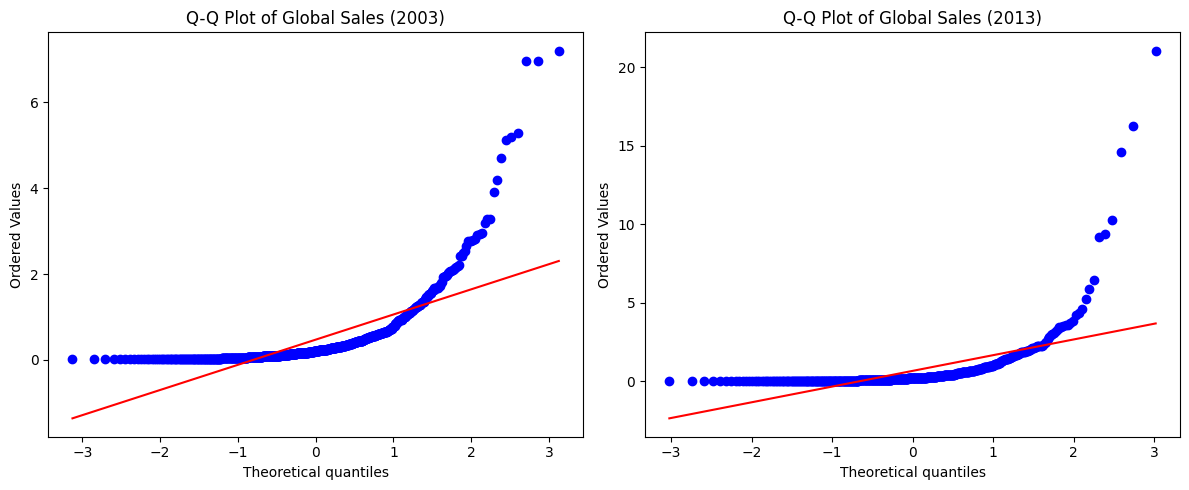

T-statistic: -2.809
P-value: 0.005
Degrees of freedom: 1331
Reject the null hypothesis.
Mean sales in 2003: 0.47
Mean sales in 2013: 0.66

ANOVA Results:
F-statistic: 20.932
P-value: 0.000000000
Reject the null hypothesis: statistically significant difference across at least two platforms.

Mean sales by platform:
Wii: 0.70
NES: 2.56
GB: 2.59
DS: 0.38
X360: 0.77
PS3: 0.71
PS2: 0.59
SNES: 0.83
GBA: 0.39
PS4: 0.81
3DS: 0.51
N64: 0.69
PS: 0.63
XB: 0.32
PC: 0.27
2600: 0.73
PSP: 0.25
XOne: 0.64
WiiU: 0.60
GC: 0.38
GEN: 1.06
DC: 0.31
PSV: 0.13
SAT: 0.20
SCD: 0.31
WS: 0.24
NG: 0.12
TG16: 0.08
3DO: 0.03
GG: 0.04
PCFX: 0.03

--- Multiple Linear Regression Summary (with Critic_Score and Rating) ---
                            OLS Regression Results                            
Dep. Variable:           Global_Sales   R-squared:                       0.171
Model:                            OLS   Adj. R-squared:                  0.162
Method:                 Least Squares   F-statistic:             

In [2]:
from scipy import stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Load video game sales dataset
df = pd.read_csv('Video_Games.csv')

# Compare global sales distributions between 2003 and 2013 using Q-Q plots
df_filtered = df.dropna(subset=['Year_of_Release']).copy()
df_filtered['Year_of_Release'] = df_filtered['Year_of_Release'].astype(int)

sales_2003 = df_filtered[df_filtered['Year_of_Release'] == 2003]['Global_Sales'].dropna()
sales_2013 = df_filtered[df_filtered['Year_of_Release'] == 2013]['Global_Sales'].dropna()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
stats.probplot(sales_2003, plot=plt)
plt.title('Q-Q Plot of Global Sales (2003)')

plt.subplot(1, 2, 2)
stats.probplot(sales_2013, plot=plt)
plt.title('Q-Q Plot of Global Sales (2013)')

plt.tight_layout()
plt.show()


def two_sample_t_test_equal_var(group1_data, group2_data):
    """Perform a two-sample t-test assuming equal population variances."""
    n1 = len(group1_data)
    n2 = len(group2_data)
    mean1 = np.mean(group1_data)
    mean2 = np.mean(group2_data)

    # Pooled variance estimator with degrees of freedom n1 + n2 - 2
    pooled_var = (
        (n1 - 1) * np.var(group1_data, ddof=1) + (n2 - 1) * np.var(group2_data, ddof=1)
    ) / (n1 + n2 - 2)

    se = np.sqrt(pooled_var * (1 / n1 + 1 / n2))
    t_statistic = (mean1 - mean2) / se
    degrees_of_freedom = n1 + n2 - 2
    p_value = 2 * stats.t.cdf(-abs(t_statistic), degrees_of_freedom)

    return t_statistic, p_value, degrees_of_freedom


sales_2003_list = sales_2003.tolist()
sales_2013_list = sales_2013.tolist()

t_stat, p_val, degrees_freedom = two_sample_t_test_equal_var(sales_2003_list, sales_2013_list)

print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:.3f}")
print(f"Degrees of freedom: {degrees_freedom}")

alpha = 0.05
if p_val < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

print(f"Mean sales in 2003: {sales_2003.mean():.2f}")
print(f"Mean sales in 2013: {sales_2013.mean():.2f}")


def analyze_platform_success(data, sales_column='Global_Sales', platform_column='Platform'):
    """Run a one-way ANOVA to test whether mean sales differ across platforms."""
    platforms = data[platform_column].dropna().unique()
    sales_by_platform = [
        data[data[platform_column] == platform][sales_column].dropna().values
        for platform in platforms
    ]

    f_statistic, p_value = stats.f_oneway(*sales_by_platform)

    print("\nANOVA Results:")
    print(f"F-statistic: {f_statistic:.3f}")
    print(f"P-value: {p_value:.9f}")

    alpha_level = 0.05
    if p_value < alpha_level:
        print("Reject the null hypothesis: statistically significant difference across at least two platforms.")
    else:
        print("Fail to reject the null hypothesis: no statistically significant difference across platforms.")

    print("\nMean sales by platform:")
    for platform in platforms:
        mean_sale = data[data[platform_column] == platform][sales_column].mean()
        print(f"{platform}: {mean_sale:.2f}")


analyze_platform_success(df)

# Filter to top publishers and genres to avoid sparse categorical dummy variables
df_cleaned = df.dropna(subset=[
    'Year_of_Release', 'Global_Sales', 'Platform', 'Publisher', 'Genre', 'Critic_Score', 'Rating'
]).copy()

df_cleaned['Year_of_Release'] = df_cleaned['Year_of_Release'].astype(int)

top_publishers = df_cleaned['Publisher'].value_counts().nlargest(50).index
top_genres = df_cleaned['Genre'].value_counts().nlargest(20).index

df_filtered_for_regression = df_cleaned[
    df_cleaned['Publisher'].isin(top_publishers) &
    df_cleaned['Genre'].isin(top_genres)
].copy()

for col in ['Platform', 'Publisher', 'Genre', 'Rating']:
    df_filtered_for_regression[col] = df_filtered_for_regression[col].astype('category')

formula = 'Global_Sales ~ C(Platform) + Year_of_Release + C(Publisher) + C(Genre) + Critic_Score + C(Rating)'

model = smf.ols(formula=formula, data=df_filtered_for_regression)
results = model.fit()

print("\n--- Multiple Linear Regression Summary (with Critic_Score and Rating) ---")
print(results.summary())